# Exercices 10

[Télécharger l'exercice](../10_exercice.zip)


# Equation de la glace en 1D

L'objectif ici est de modéliser l'évolution d'un glacier synthétique (idéalisé) en resolvant l'équation de la glace en 1D. L'évolution de la géométrie d'un glacier / calotte glaciaire peut être approximée par un processus de diffusion non linéaire. L'équation de diffusion non linéaire en une dimension, qui prédit l'évolution de la géométrie d'une calotte glaciaire, est la suivante :

$$\frac{\partial h}{\partial t} = - \frac{\partial q_x}{\partial x} + b(s), \qquad (1)$$

$$q_x = - D(h) \frac{\partial s}{\partial x},$$

où $h$ est la hauteur de glace, $l$ est l'altitude du lit rocheux, $s = l+h$ est l'altitude de la surface de glace, $D(h)$ est la diffusivité dynamique de la glace, $b$ est le bilan de masse (accumulation moins ablation de glace en surface), $t$ est le temps, et $x$ est la distance le long du modèle.  

La non-linéarité dans la diffusion vient de la diffusivité dynamique $D(h)$, qui elle-même dépend de l'épaisseur locale de la glace $h$ et de la pente de sa surface :

$$D(h) = f_d (\rho g)^3 h^5 \left( \frac{\partial s}{\partial x} \right)^2,$$

où $f_d$ est une constante physique, $\rho$ est la densité de la glace, et $g$ est la constante de gravité. La diffusivité doit donc être mise à jour au cours du temps.

Le fonction "bilan de masse" est définit par la formule suivante

$$b(s) = \min ( b_\mathrm{grad} (s-s_\mathrm{ELA}), b_\mathrm{max} ).$$
 
ou $b_\mathrm{grad}$, $s_\mathrm{ELA}$, et $b_\mathrm{max}$ sont des paramètres.

Écrivez le code d'un modèle de glacier en 1D en discrétisant l'équation (1). Utilisez une épaisseur de glace initiale de 0 m. Comme conditions limites, fixez l'épaisseur de glace aux deux extrémités du modèle à une épaisseur de glace nulle. Les paramètres additionnels sont donnés dans la table suivante. Utilisez la fonction logarithmique suivante pour définir un lit rocheux synthétique :
 
$$l(x)  = 11522.8 - 1000 \times log(x + 1000).$$

Visualisez l'évolution temporelle des résultats du modèle dans une figure comme dans la figure suivante. 

Modifiez les paramètres de la fonction bilan de masse $b$, et explorez leur influence sur le résultat.
 
![](fig/sol_glacier_1D.png)

*Résultat du modèle de glacier 1D.*

| **Paramètres**                             | **Valeurs**                 |
|--------------------------------------------|-----------------------------|
| constante physique $ f_d $               | $1.0 \; 10^{-16} [Pa^{-3} yr^{-1}]$ |
| longueur du modèle $ L $                | 100 km                      |
| épaisseur initiale de la glace             | 0 m                         |
| pas de temps maximal $ dt_{max} $       | 1 y                         |
| densité de la glace $ \rho_{\mathrm{ice}} $ | 910 $kg/m^{3}$         |
| constante de gravité $ g $              | 9.81 $m s^{-2}$          |
| altitude de la ligne d'équilibre $ z_{\mathrm{ELA}} $ | 1200 m             |
| bilan de masse maximum $ b_{\mathrm{max}} $ | 0.3 m/yr                 |
| gradient du bilan de masse $ b_{\mathrm{grad}} $ | 0.001                  |
| temps total                                | 3000 y                     |

*Paramètres pour les exercices.*
 
### ✅ **À vous de faire !** 


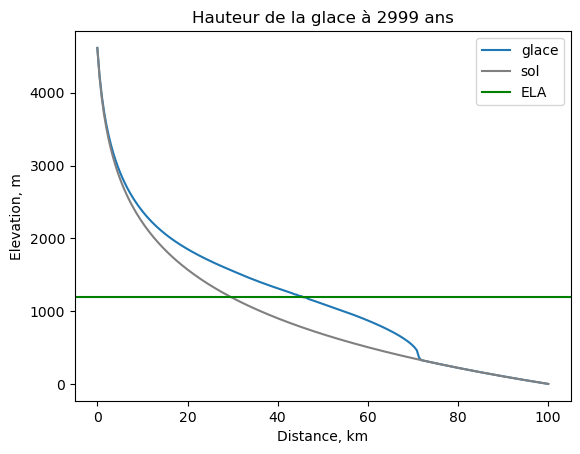

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# ! CORRECTION:
# Overall, great job! The code is working well and the solution looks correct.

# PHYSICAL PARAMETERS
fd = 1e-16
Lx = 100000                     # longueur du modèle en m
h_ini = 0                       # épaisseur initiale de la galce en m
rho_ice = 910                   # densité de la glacce en kg/m3
g = 9.81                        # gravité em m/s2
z_ela = 1200                    # altitude ligne d'équilible en m
b_max = 0.3                     # bilan de masse max en m/an
b_grad = 0.001                  # gradient du bilan de masse
cstd = fd*(rho_ice*g)**3

# NUMERICAL PARAMETERS
nx = 200                        # nombre de cellules
dx = Lx / (nx - 1)              # taille d'une cellule
x = np.linspace(0, Lx, nx)      # coordonees des point du maillage
dtmax = 1                       # pas de temps max (1 an)
ttot = 3000                     # temps total en années
nt = int(1e6)                   # nombre de pas de temps (arbitraire car ne peut pas être calculé)
nout = 250                      # affichage toutes les nout ittérations

# INITIALIZATION
l = 11522.8-1000*np.log(x+1000)         # hauteur du lit
h = np.ones(nx)*h_ini                   # hauteur de glace (0 au départ)
s = l + h                               # hauteur initiale de la surface de la glace
time = 0                                # initialisation du temps

# create the figure outside the loop 
fig, ax = plt.subplots()

# loop
# ! CORRECTION
# Consider a while loop instead as then you do not have to have an arbitary large nt.
# What you did is correct as long as you break out of the loop, but just so you know :)
for it in range(nt):
    hm = 0.5*(h[1:]+h[:-1])                             # points milieux de la hauteur de glace
    dsdx = (s[1:]-s[:-1])/dx                            # dérivée de la pente
    D = cstd*(hm**5)*(dsdx**2)                          # calcul de la diffusivité (dépend de h qui change au cours du temps)
    dt = min(dtmax, (dx**2)/(2.1*np.max(np.abs(D))))    # condition sur le pas de temps
    bs = np.minimum((b_grad*(s-z_ela)), b_max)          # bilan de masse
    q = - D * dsdx                                      # flux de glace
    dhdt = - (( q[1:] - q[:-1] ) / dx) + bs[1:-1]       # évolution de la couche de glace dans le temps
    h[1:-1] += dhdt * dt                                # mise à jour de la surface de glace

    # boundary conditions
    h[0]= 0                         # bord gauche
    h[-1]= 0                        # bord droit
    h[h<0] = 0                      # tout le modèle doit avoir une hauteur de glace >= 0

    s = l + h                       # mise à jour de la hauteur totale (sol + glace)
    time += dt                      # mise à jour du temps

    if time >= ttot:
        break                       # quitter la boucle une fois le temps total atteint

    # plot
    if it % nout == 0:
        clear_output(wait=True) 
        ax.cla() 
        ax.plot(x/1000, s, label='glace')
        ax.plot(x/1000, l, label='sol', color='grey')
        ax.axhline(z_ela, label='ELA', color='green')
        ax.set_title(f'Hauteur de la glace à {round(time)} ans')
        ax.set_xlabel('Distance, km')
        ax.set_ylabel('Elevation, m')
        ax.legend()
        display(fig)
        # plt.pause(0.1)